In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [2]:
df.head(50).to_csv("archivo_reducido.csv", index=False)


In [3]:
df.head(1)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers


In [4]:
crosstab_counts = pd.crosstab(df['category'], df['isBestSeller'])
print(crosstab_counts.columns)


Index([False, True], dtype='bool', name='isBestSeller')


In [5]:
crosstab_counts['Proportion_BestSeller'] = crosstab_counts[True] / (crosstab_counts[True] + crosstab_counts[False])


In [6]:
crosstab_sorted = crosstab_counts.sort_values('Proportion_BestSeller', ascending=False)

In [7]:
print(crosstab_sorted)

isBestSeller                      False  True  Proportion_BestSeller
category                                                            
Grocery                            9008   556               0.058135
Smart Home Security & Lighting       98     6               0.057692
Health & Personal Care             9017   552               0.057686
Mobile Phone Accessories            248    11               0.042471
Power & Hand Tools                 8353   306               0.035339
...                                 ...   ...                    ...
CD, Disc & Tape Players            8798     0               0.000000
General Music-Making Accessories    259     0               0.000000
Snowboard Boots                    1449     0               0.000000
Boxes & Organisers                  911     0               0.000000
eBook Readers & Accessories         246     0               0.000000

[296 rows x 3 columns]


In [8]:
from scipy.stats import chi2_contingency
import numpy as np
from scipy.stats.contingency import association

# Chi-square
chi2, p, dof, expected = chi2_contingency(crosstab_counts[[0,1]])

print(f"Chi-square: {chi2:.2f}, p-value: {p:.4f}, degrees of freedom: {dof}")

# Cramér's V
def cramers_v(confusion_matrix):
    chi2_val = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2_val / (n * (min(r, k) - 1)))

v = cramers_v(crosstab_counts[[0,1]])
print(f"Cramér's V: {v:.3f}")


Chi-square: 36540.20, p-value: 0.0000, degrees of freedom: 295
Cramér's V: 0.122


Parte2


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()


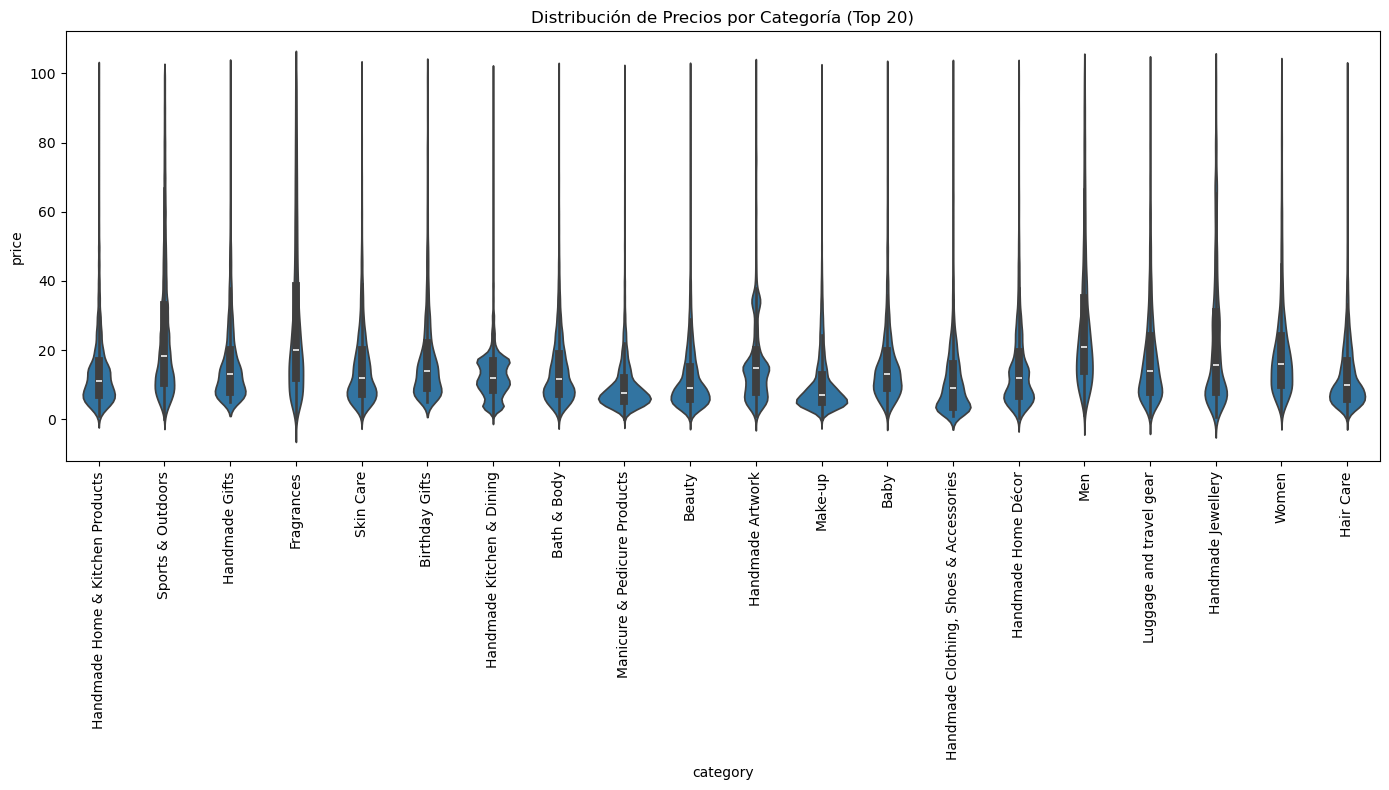

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

top20_cats = df_clean['category'].value_counts().head(20).index
df_top20 = df_clean[df_clean['category'].isin(top20_cats)]

plt.figure(figsize=(14, 8))
sns.violinplot(x='category', y='price', data=df_top20)
plt.xticks(rotation=90)
plt.title('Distribución de Precios por Categoría (Top 20)')
plt.tight_layout()
plt.show()

In [ ]:
medians = df_clean.groupby('category')['price'].median().sort_values(ascending=False)
print("Categoría con mayor precio mediano:", medians.index[0])

Categoría con mayor precio mediano: Desktop PCs


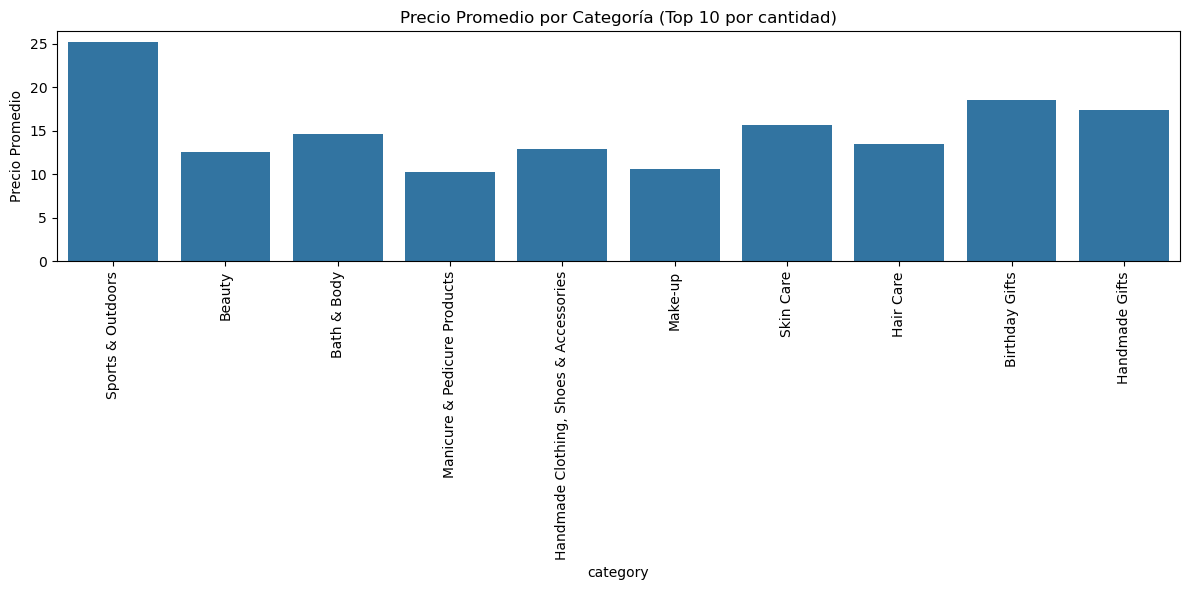

Categoría con mayor precio promedio: Motherboards


In [ ]:
avg_price = df_clean.groupby('category').agg({'price': ['mean', 'count']})
avg_price.columns = ['avg_price', 'count']
top10_by_count = avg_price.sort_values('count', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top10_by_count.index, y=top10_by_count['avg_price'])
plt.xticks(rotation=90)
plt.title('Precio Promedio por Categoría (Top 10 por cantidad)')
plt.ylabel('Precio Promedio')
plt.tight_layout()
plt.show()

overall_avg = df_clean.groupby('category')['price'].mean().sort_values(ascending=False)
print("Categoría con mayor precio promedio:", overall_avg.index[0])


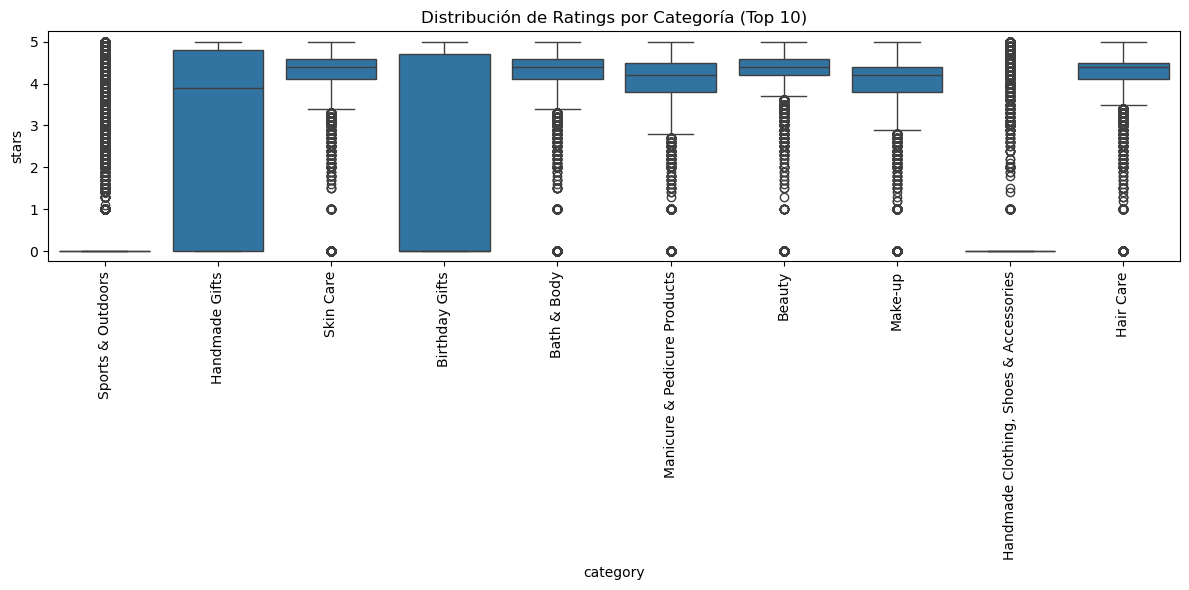

In [ ]:
top10_rating_cats = df_clean['category'].value_counts().head(10).index
df_top10_ratings = df_clean[df_clean['category'].isin(top10_rating_cats)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=df_top10_ratings)
plt.xticks(rotation=90)
plt.title('Distribución de Ratings por Categoría (Top 10)')
plt.tight_layout()
plt.show()


In [15]:
med_rating = df_clean.groupby('category')['stars'].median().sort_values(ascending=False)
print("Categoría con mayor rating mediano:", med_rating.index[0])


Categoría con mayor rating mediano: Computer Memory


Parte3

In [ ]:
correlation = df_clean['price'].corr(df_clean['stars'], method='pearson')
print(f"Coeficiente de correlación (Pearson) entre precio y stars: {correlation:.3f}")


Coeficiente de correlación (Pearson) entre precio y stars: -0.078


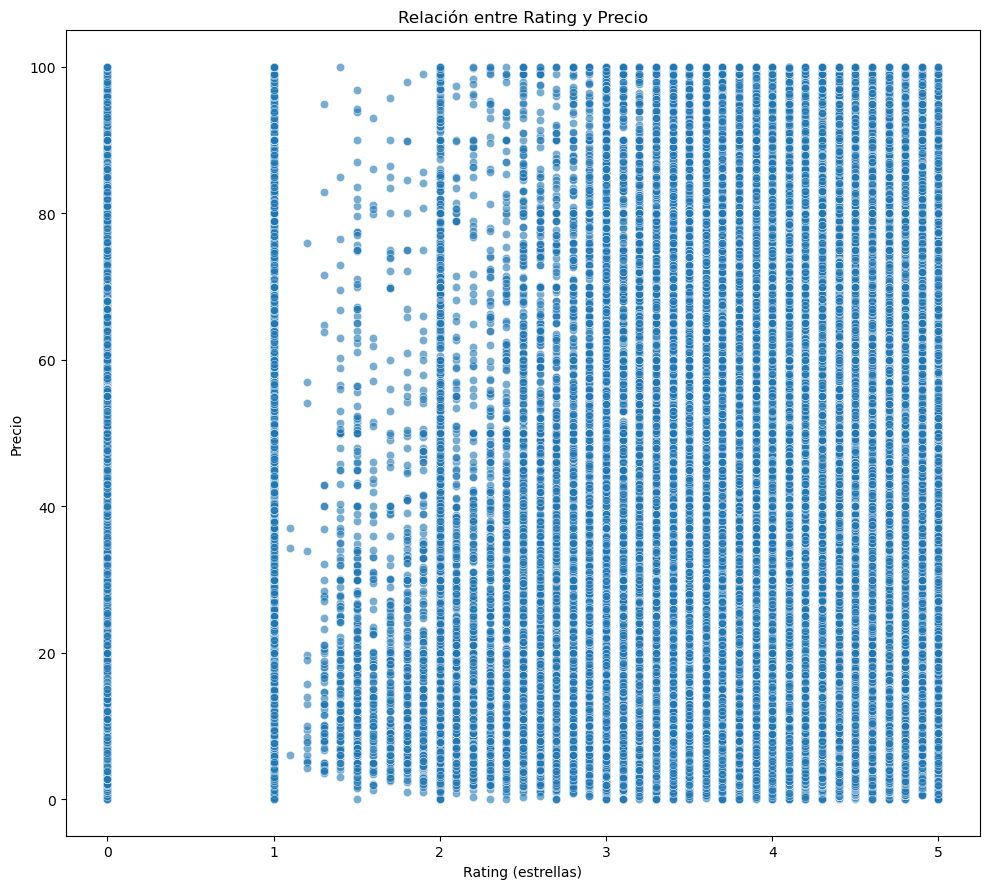

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 9))
sns.scatterplot(data=df_clean, x='stars', y='price', alpha=0.6)
plt.title("Relación entre Rating y Precio")
plt.xlabel("Rating (estrellas)")
plt.ylabel("Precio")
plt.tight_layout()
plt.show()


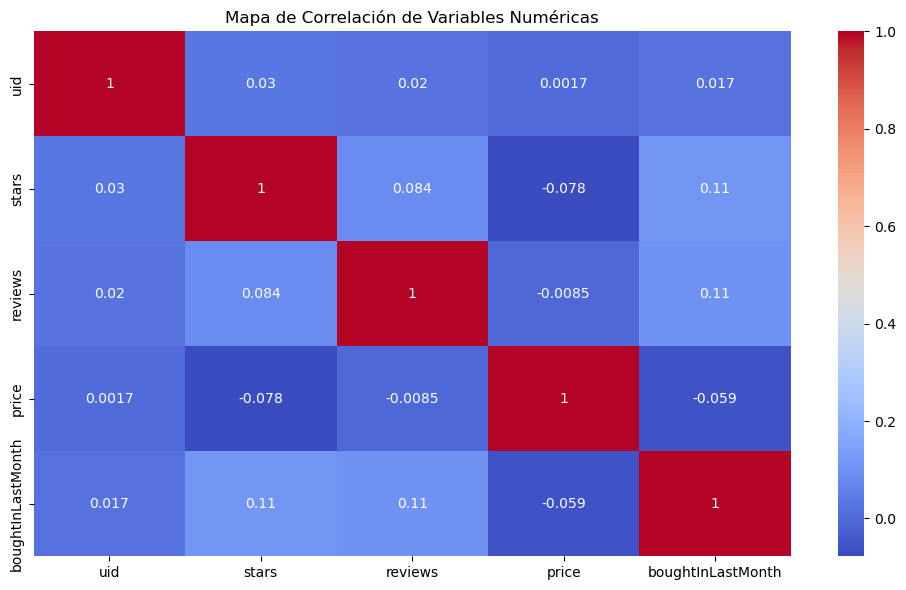

In [21]:
num_df = df_clean.select_dtypes(include='number')

cor_matrix = num_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(cor_matrix, annot=True, cmap='coolwarm')
plt.title("Mapa de Correlación de Variables Numéricas")
plt.tight_layout()
plt.show()


In [ ]:
# QQ Plot para precios

stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title("QQ Plot de Precio")
plt.tight_layout()
plt.show()
